# Rolling κ: episode-level mean-reversion estimate

这份研究 notebook 从零开始，不沿用逐点 $\lambda=\Delta z/z$。先只构造一个固定窗口、用于下一根预测的 $\hat\kappa$；暂不计算 life，也不形成交易信号。

假设 z-score 落在 $[-0.25,0.25]$ 时属于中性区。进入中性区是有效的回归信息；从中性区重新离开时，距离的起点为零，因而自然不贡献 OLS 统计。为与此前识别出的 14 根 overshoot bar 对齐，本 notebook 暂以分母按 $\pm0.25$ 补齐后的初算 $\lambda_{\mathrm{initial}}\leq-1$ 标记 crossing/reset，并将这些 transition 排除。

## 1. 先定义对象：bar、距离与 transition

令 $S_t$ 是第 $t$ 个交易日收盘时的 fixed-beta spread；$\mu_t,\sigma_t$ 是只用截至该日数据计算的 20 日 rolling mean 与 rolling standard deviation；$z_t=(S_t-\mu_t)/\sigma_t$。横轴只按连续交易日编号，因此周末和节假日不构成额外的 transition。

中性区是 $[-0.25,0.25]$。我们只量度离开这个区间后的**绝对距离**：

$$r_t=\max(|z_t|-0.25,0).$$

一个候选 transition 是相邻交易日的有方向边：$t-1\rightarrow t$，其被建模的响应变量为 $\Delta r_t=r_t-r_{t-1}$。它只有同时满足以下条件时才是 **usable transition**：

1. $z_{t-1}$、$z_t$ 都存在（因此前 20 根滚动窗口未完成的 bar 不参与）；
2. $r_{t-1}>0$，即 transition 从中性区外开始；
3. 第 $t$ 根不是预先标记的 crossing/reset bar（目前与旧图的 14 根定义对齐）。

因此，**从区间外回到中性区**仍会被统计：它有 $r_{t-1}>0,r_t=0$，并提供回归证据。反过来，**从中性区第一次离开**不会被统计：它有 $r_{t-1}=0$，既没有可拟合的方向，也会使回归的分母贡献为零。这正是把“从 0 随机选择方向发散”的第一步与后续同一 episode 的运动分开的原因。

## 2. 读取数据并构造 spread

下面的代码 cell 做四件事：导入库；读取 SBLK 与 BHP 在同一交易日出现的日线；以 endpoint-detrended 的最小方差公式求固定 $\beta$；最后计算 spread、20 日 $\mu$、$\sigma$ 与 z-score。它不估计 $\kappa$，也不循环遍历 episode。数据库连接设有超时，若不能连上会报错而非无限等待。

输出最后五根数据，供检查数据起点、共同交易日数量及 fixed beta。

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pymysql

TICKER_Y, TICKER_X = 'SBLK', 'BHP'
START_DATE = '2026-01-02'
ROLLING_DAYS = 20
BARS_PER_TRADING_DAY_5M = 79
ROLLING_WINDOW = ROLLING_DAYS  # 本 notebook 读取日线；5 分钟对应 ROLLING_DAYS * BARS_PER_TRADING_DAY_5M = 1580 bars
KAPPA_ROLLING_WINDOW = ROLLING_WINDOW
NEUTRAL_BOUNDARY = 0.25
# 连接和读取均设定超时：数据库不可用时会报错，而不是让 notebook 一直显示忙碌。
DB_CONFIG = {
    'host': 'localhost', 'user': 'quant', 'password': '1q2w3e', 'database': 'quant_data',
    'connect_timeout': 10, 'read_timeout': 30, 'write_timeout': 30,
}

query = '''
SELECT a.trade_date AS date, a.price AS y_price, b.price AS x_price
FROM us_market_days AS a
JOIN us_market_days AS b ON b.ticker = %(ticker_x)s AND b.trade_date = a.trade_date
WHERE a.ticker = %(ticker_y)s AND a.trade_date >= %(start_date)s
ORDER BY a.trade_date
'''
print('Loading aligned SBLK / BHP trading-day bars …')
with pymysql.connect(**DB_CONFIG) as connection:
    data = pd.read_sql(query, connection, params={'ticker_y': TICKER_Y, 'ticker_x': TICKER_X, 'start_date': START_DATE})

data['date'] = pd.to_datetime(data['date'])
data[['y_price', 'x_price']] = data[['y_price', 'x_price']].apply(pd.to_numeric, errors='coerce')
data = data.dropna().drop_duplicates('date').sort_values('date').reset_index(drop=True)

def endpoint_detrend(values):
    values = np.asarray(values, dtype=float)
    return values - np.linspace(values[0], values[-1], len(values))

dy, dx = endpoint_detrend(data['y_price']), endpoint_detrend(data['x_price'])
beta_fixed = float(np.dot(dx, dy) / np.dot(dx, dx))
data['spread'] = data['y_price'] - beta_fixed * data['x_price']
data['mu'] = data['spread'].rolling(ROLLING_WINDOW, min_periods=ROLLING_WINDOW).mean()
data['sigma'] = data['spread'].rolling(ROLLING_WINDOW, min_periods=ROLLING_WINDOW).std(ddof=0)
data['zscore'] = (data['spread'] - data['mu']) / data['sigma']
data['trading_bar'] = np.arange(len(data))

print(f'fixed beta = {beta_fixed:.6f}; common trading bars = {len(data)}')
data[['date', 'spread', 'mu', 'sigma', 'zscore']].tail()

Loading aligned SBLK / BHP trading-day bars …
fixed beta = 0.167199; common trading bars = 140


/tmp/ipykernel_1981307/196925776.py:28: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  data = pd.read_sql(query, connection, params={'ticker_y': TICKER_Y, 'ticker_x': TICKER_X, 'start_date': START_DATE})


,date,spread,mu,sigma,zscore
135,2026-07-20,12.632172,12.100663,0.760389,0.698997
136,2026-07-21,12.727263,12.128141,0.772509,0.775553
137,2026-07-22,12.635017,12.098497,0.740449,0.724587
138,2026-07-23,13.163824,12.148002,0.776065,1.308939
139,2026-07-24,14.142120,12.267101,0.882834,2.123863


## 3. 构造 $r_t$，并暂时识别 14 根

这一步先计算 $r_t$。随后仅为了与旧的 instant-lambda 图保持一致，计算一个**参考判据**：将上一根 z-score 的绝对值至少补到 $0.25$，并取

$$\lambda_{\mathrm{initial},t}=\frac{S_t-S_{t-1}}{\sigma_{t-1}\,\operatorname{sign}(z_{t-1})\max(|z_{t-1}|,0.25)}.$$

当 $\lambda_{\mathrm{initial},t}\leq-1$ 时，标记 `crossing_event=True`。在当前 SBLK/BHP 样本及参数下，这精确复现先前的 14 根 bar。它只是临时的 reset 标签，不是本 notebook 的最终 $\kappa$ 定义，也不会作为连续数值加入回归。输出末尾 15 行供逐行核对。

In [10]:
# r 是离开中性区的距离；与既有 14 根 overshoot transition 对齐的事件单独排除。
data['r'] = (data['zscore'].abs() - NEUTRAL_BOUNDARY).clip(lower=0)
previous_z = data['zscore'].shift(1)
previous_sigma = data['sigma'].shift(1)
previous_z_used = np.sign(previous_z) * np.maximum(previous_z.abs(), NEUTRAL_BOUNDARY)
previous_z_used = previous_z_used.where(previous_z.notna() & previous_z.ne(0))
data['lambda_initial_reference'] = data['spread'].diff() / (previous_z_used * previous_sigma)
# 仅用初算 lambda <= -1 识别 overshoot；不使用任何后续符号反转。
data['crossing_event'] = data['lambda_initial_reference'].le(-1)
data[['date', 'zscore', 'r', 'lambda_initial_reference', 'crossing_event']].tail(15)

,date,zscore,r,lambda_initial_reference,crossing_event
125,2026-07-06,0.549048,0.299048,-1.674627,True
126,2026-07-07,1.619732,1.369732,1.839611,False
127,2026-07-08,2.166376,1.916376,0.574792,False
128,2026-07-09,0.923664,0.673664,-0.551495,False
129,2026-07-10,1.101133,0.851133,0.260055,False
130,2026-07-13,1.297684,1.047684,0.295185,False
131,2026-07-14,0.645217,0.395217,-0.472975,False
132,2026-07-15,0.114320,0.000000,-0.784814,False
133,2026-07-16,0.634003,0.384003,2.381072,False
134,2026-07-17,-0.780486,0.530486,-2.265619,True


## 4. Rolling $\hat\kappa$：最近 20 个交易日的 episode-level 均值回复估计

这一节回答一个朴素问题：**在最近 20 个交易日内，从中性区外开始的那些日子，距离 $r$ 通常以多快的比例缩小或扩大？** 日线使用 20 根 bar；若输入改为 5 分钟 bar，则与 Fixed Beta dashboard 一致，窗口固定为 $20\times79=1580$ 根 bar。

### 4.1 先看一根 transition

对于一根 usable transition $i-1\rightarrow i$，我们已有起点距离 $r_{i-1}>0$ 和变化量 $\Delta r_i=r_i-r_{i-1}$。若只看这一根，它给出的即时比例是：

$$\frac{\Delta r_i}{r_{i-1}}.$$

例如，$r$ 从 $2$ 变成 $1$，则 $\Delta r=-1$，比例是 $-1/2=-0.5$：这根 bar 表现为距离收缩 50%。若 $r$ 从 $1$ 变成 $1.2$，比例是 $+0.2$：这根 bar 表现为扩大 20%。

但我们已经见过逐点 lambda 的问题：单根比例很容易受偶然跳动影响。因此不直接把这一根的比例叫作状态，而是把很多根有效 transition 合在一起。

### 4.2 要拟合的关系到底是什么？

我们假设同一阶段中，每根 transition 大致满足：

$$\Delta r_i\approx\kappa r_{i-1}. $$

这里没有截距。原因很直观：若起点就在中性区边缘以内，$r_{i-1}=0$，模型不应凭空规定距离必然增加或减少多少；中性区离开的第一步被视为方向选择，而不是回归速度的样本。

$\kappa=-0.3$ 的读法是：在**当前滚动窗口**内，区间外距离平均倾向在一根 bar 后减少约自身的 30%。$\kappa=0$ 是“没有平均收缩力”；$\kappa>0$ 才是“距离平均继续扩大”。这是对 $r$ 的变化率，不是 spread 本身的涨跌率。

### 4.3 最小二乘：让一条线尽量贴近很多根 bar

对任何候选 $k$，第 $i$ 根的预测是 $k r_{i-1}$，实际是 $\Delta r_i$，两者之差是误差：

$$e_i=\Delta r_i-k r_{i-1}. $$

最小二乘的意思只是选择一个 $k$，使所有误差的平方和最小：

$$\text{选择 }k\text{，让 }\sum e_i^2\text{ 最小。}$$

平方会避免正、负误差互相抵消，也会让明显不吻合的点受到更大惩罚。这个最优斜率就是普通最小二乘的 $\hat\kappa$。

### 4.4 固定窗口，而非无限累计

市场状态会变化，所以本版本不让很久以前的 transition 一直保留影响。令 $W=20$ 个交易日（5 分钟数据时 $W=1580$ 根 bar），每个时点只拟合最近窗口内的 usable transition：

$$\hat\kappa_t=\frac{\sum_{i=t-W+1}^{t}\mathbf{1}_{i\in\mathcal U}r_{i-1}\Delta r_i}{\sum_{i=t-W+1}^{t}\mathbf{1}_{i\in\mathcal U}r_{i-1}^2}. $$

不可用 transition 在窗口内不贡献分子或分母；窗口本身仍固定向前滚动。因此状态变化最多在旧 evidence 离开窗口后完全反映出来，而不会像无限累计那样保留遥远历史。

### 4.5 当前 bar 的因果性

当前行只使用截至当前收盘已经完成的 transition；若以后要做预测，才可把它带到下一根：$E[r_{t+1}|\mathcal F_t]=(1+\hat\kappa_t)r_t$。下一格代码分别保留 rolling OLS 的分子、分母和 `transition_used`，方便逐行审计。

In [11]:
# 固定 20 日 rolling OLS：每根只使用截至当前的最近 KAPPA_ROLLING_WINDOW 根 transition。
r_prev = data['r'].shift(1)
delta_r = data['r'] - r_prev
transition_used = (~data['crossing_event'] & r_prev.notna() & data['r'].notna() & r_prev.gt(0))
# 不可用 transition 在窗口中不贡献 OLS 的分子或分母。
data['kappa_numerator_term'] = (r_prev * delta_r).where(transition_used, 0.0)
data['kappa_denominator_term'] = (r_prev ** 2).where(transition_used, 0.0)
data['kappa_numerator'] = data['kappa_numerator_term'].rolling(KAPPA_ROLLING_WINDOW, min_periods=KAPPA_ROLLING_WINDOW).sum()
data['kappa_denominator'] = data['kappa_denominator_term'].rolling(KAPPA_ROLLING_WINDOW, min_periods=KAPPA_ROLLING_WINDOW).sum()
data['kappa_hat'] = (data['kappa_numerator'] / data['kappa_denominator']).where(data['kappa_denominator'] > 1e-12)
data['transition_used'] = transition_used
data['predicted_next_r'] = np.where(data['r'].notna() & data['kappa_hat'].notna(),
                                    (1 + data['kappa_hat']) * data['r'], np.nan)

print(f'usable within-episode transitions: {transition_used.sum()}')
print(f'direct crossing transitions excluded: {data["crossing_event"].sum()}')
data[['date', 'zscore', 'r', 'crossing_event', 'transition_used', 'kappa_hat', 'predicted_next_r']].tail(20)

usable within-episode transitions: 86
direct crossing transitions excluded: 22


,date,zscore,r,crossing_event,transition_used,kappa_hat,predicted_next_r
120,2026-06-26,-1.841425,1.591425,False,True,-0.586749,0.657658
121,2026-06-29,-1.462794,1.212794,False,True,-0.537129,0.561366
122,2026-06-30,-1.216675,0.966675,False,True,-0.511628,0.472097
123,2026-07-01,-1.136483,0.886483,False,True,-0.491807,0.450505
124,2026-07-02,-0.858530,0.608530,False,True,-0.498327,0.305283
125,2026-07-06,0.549048,0.299048,True,False,-0.479114,0.155770
126,2026-07-07,1.619732,1.369732,False,True,-0.459794,0.739937
127,2026-07-08,2.166376,1.916376,False,True,-0.267885,1.403007
128,2026-07-09,0.923664,0.673664,False,True,-0.333260,0.449159
129,2026-07-10,1.101133,0.851133,False,True,-0.320489,0.578354


In [12]:
# 同一固定窗口的 rolling-mean derivative / bar；只使用当前及窗口前的 spread。
data['mean_derivative'] = (data['spread'] - data['spread'].shift(ROLLING_WINDOW)) / ROLLING_WINDOW
print(f'rolling window = {ROLLING_WINDOW} daily bars; 5-minute equivalent = {ROLLING_DAYS * BARS_PER_TRADING_DAY_5M} bars')
data[['date', 'spread', 'mu', 'mean_derivative']].tail(20)

rolling window = 20 daily bars; 5-minute equivalent = 1580 bars


,date,spread,mu,mean_derivative
120,2026-06-26,10.853556,11.907301,-0.057320
121,2026-06-29,10.973173,11.861742,-0.045559
122,2026-06-30,11.040671,11.791869,-0.069873
123,2026-07-01,11.062918,11.778743,-0.013126
124,2026-07-02,11.217327,11.765610,-0.013133
125,2026-07-06,12.135496,11.782080,0.016470
126,2026-07-07,12.785643,11.771896,-0.010184
127,2026-07-08,13.368337,11.828540,0.056644
128,2026-07-09,12.519147,11.849835,0.021295
129,2026-07-10,12.693205,11.873952,0.024117


## 5. 读图

上图显示 z-score 与灰色中性区，用来观察 episode 的进入、离开和跨越。下图显示每根收盘后可得到的 20 日 rolling $\hat\kappa_t$：蓝色填充代表窗口内回归证据，红色填充代表窗口内发散证据。这张图不是逐点 instant lambda，也尚未把 $\kappa$ 转为 life；下一步将先检验它对 $r_{t+1}$ 的样本外预测是否稳定。

<>:8: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
<>:12: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
<>:8: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
<>:12: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
/tmp/ipykernel_1981307/2396988021.py:8: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
  ax_kappa.plot(data['trading_bar'], data['kappa_hat'], color='#6a3d9a', lw=1.8, label='rolling $\hat\kappa_t$')
/tmp/ipykernel_1981307/2396988021.py:12: SyntaxWarning: "\h" is an invalid escape sequ

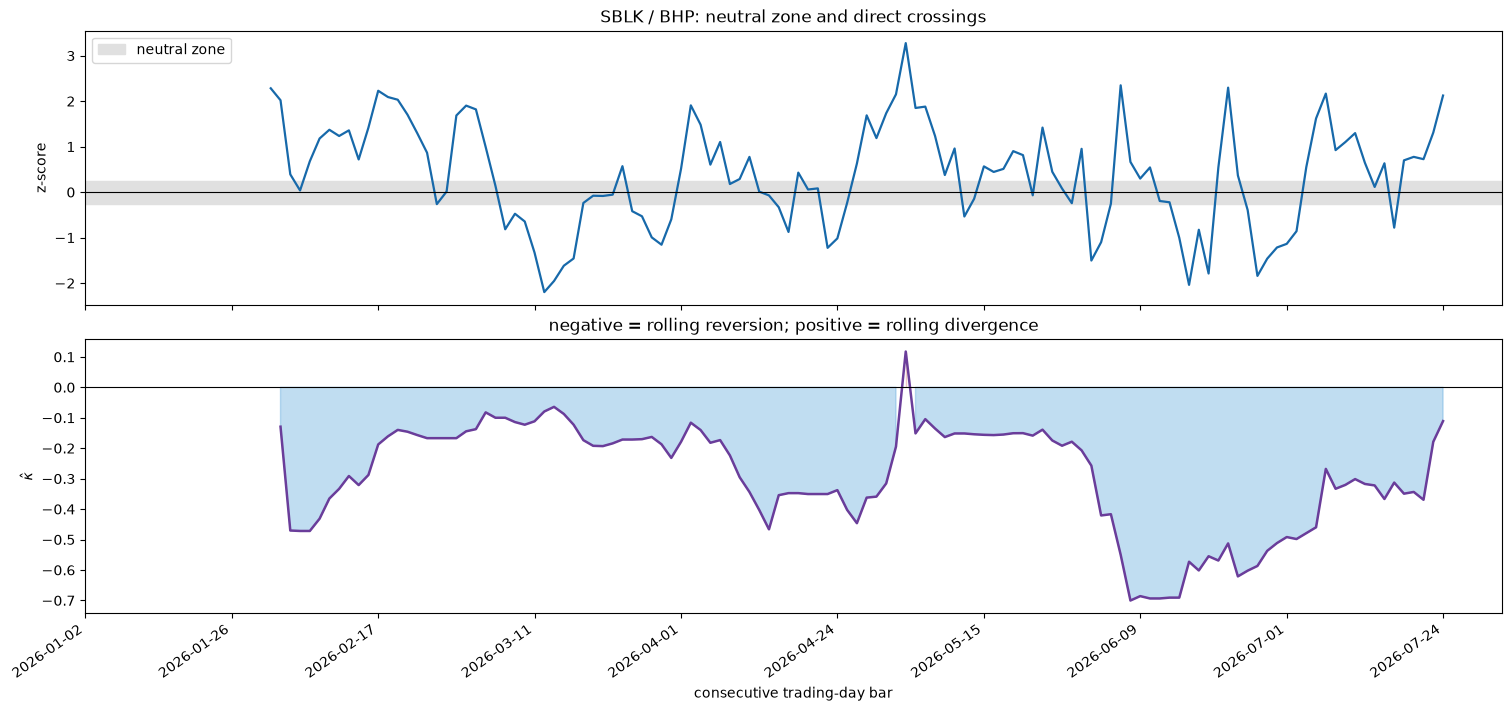

In [13]:
fig, (ax_z, ax_kappa) = plt.subplots(2, 1, figsize=(15, 7), sharex=True, constrained_layout=True)
ax_z.plot(data['trading_bar'], data['zscore'], color='#1769aa', lw=1.6)
ax_z.axhspan(-NEUTRAL_BOUNDARY, NEUTRAL_BOUNDARY, color='0.88', zorder=0, label='neutral zone')
ax_z.axhline(0, color='black', lw=0.8)
ax_z.set(ylabel='z-score', title=f'{TICKER_Y} / {TICKER_X}: neutral zone and direct crossings')
ax_z.legend(loc='upper left')

ax_kappa.plot(data['trading_bar'], data['kappa_hat'], color='#6a3d9a', lw=1.8, label='rolling $\hat\kappa_t$')
ax_kappa.axhline(0, color='black', lw=0.8)
ax_kappa.fill_between(data['trading_bar'], 0, data['kappa_hat'], where=data['kappa_hat'] < 0, color='#4c9ed9', alpha=0.35)
ax_kappa.fill_between(data['trading_bar'], 0, data['kappa_hat'], where=data['kappa_hat'] > 0, color='#d95f5f', alpha=0.35)
ax_kappa.set(xlabel='consecutive trading-day bar', ylabel='$\hat\kappa$', title='negative = rolling reversion; positive = rolling divergence')
tick_positions = np.unique(np.linspace(0, len(data) - 1, min(10, len(data)), dtype=int))
ax_kappa.set_xticks(tick_positions, data['date'].dt.strftime('%Y-%m-%d').iloc[tick_positions], rotation=35, ha='right')
plt.show()

## 6. 用同一张 $\hat\kappa$ 状态图比较两个样本

这里不做预测评分，也不划分训练/测试集。目的只是复刻第 5 节的图，观察 $\hat\kappa$ 本身在两种已知不同状态下的形状。两者都从 `2026-01-02` 开始，并各自在**完整显示样本**上固定 beta：

- SBLK/BHP：从 `us_market_prices` 取每个交易日最后一根 5 分钟 bar，因而包含比 `us_market_days` 更晚的日期；
- AA/CENX：使用 `us_market_days` 日线。这个配对被用作观察已有稳定回归段与剧烈失效段时，$\hat\kappa$ 是否会持续上移、甚至变为正。

所有 $r$、14 根同口径 crossing/reset 标签和 20 日 rolling OLS 公式都与第 5 节一致。固定 beta 使用全显示样本只是为了让图的 spread 定义在整段期间不变；这里的图是状态描述，不是前瞻预测检验。

### 6.1 读取并重建两个配对（下一格代码）

此 cell 为每个配对分别读取共同交易日、计算 fixed beta、spread、rolling z-score、$r$、crossing/reset 标签和 20 日 rolling $\hat\kappa$。输出数据区间、beta 与 reset bar 数，方便确认两张图的输入。

In [14]:
def load_display_pair(ticker_y, ticker_x, source):
    if source == 'days':
        sql = '''
        SELECT a.trade_date AS date, a.price AS y_price, b.price AS x_price
        FROM us_market_days AS a
        JOIN us_market_days AS b ON b.ticker = %(ticker_x)s AND b.trade_date = a.trade_date
        WHERE a.ticker = %(ticker_y)s AND a.trade_date >= %(start_date)s
        ORDER BY a.trade_date
        '''
    elif source == 'prices_last_bar':
        sql = '''
        WITH daily_last AS (
            SELECT ticker, DATE(time_utc) AS date, MAX(time_utc) AS last_time
            FROM us_market_prices
            WHERE ticker IN (%(ticker_y)s, %(ticker_x)s) AND time_utc >= %(start_date)s
            GROUP BY ticker, DATE(time_utc)
        )
        SELECT dy.date, y.price AS y_price, x.price AS x_price
        FROM daily_last AS dy
        JOIN us_market_prices AS y ON y.ticker = %(ticker_y)s AND y.time_utc = dy.last_time
        JOIN daily_last AS dx ON dx.ticker = %(ticker_x)s AND dx.date = dy.date
        JOIN us_market_prices AS x ON x.ticker = %(ticker_x)s AND x.time_utc = dx.last_time
        WHERE dy.ticker = %(ticker_y)s
        ORDER BY dy.date
        '''
    else:
        raise ValueError('source must be days or prices_last_bar')
    with pymysql.connect(**DB_CONFIG) as connection:
        frame = pd.read_sql(sql, connection, params={
            'ticker_y': ticker_y, 'ticker_x': ticker_x, 'start_date': START_DATE
        })
    frame['date'] = pd.to_datetime(frame['date'])
    frame[['y_price', 'x_price']] = frame[['y_price', 'x_price']].apply(pd.to_numeric, errors='coerce')
    return frame.dropna().drop_duplicates('date').sort_values('date').reset_index(drop=True)

def build_display_kappa(frame):
    out = frame.copy()
    dy, dx = endpoint_detrend(out['y_price']), endpoint_detrend(out['x_price'])
    beta = float(np.dot(dx, dy) / np.dot(dx, dx))
    out['spread'] = out['y_price'] - beta * out['x_price']
    out['mu'] = out['spread'].rolling(ROLLING_WINDOW, min_periods=ROLLING_WINDOW).mean()
    out['sigma'] = out['spread'].rolling(ROLLING_WINDOW, min_periods=ROLLING_WINDOW).std(ddof=0)
    out['zscore'] = (out['spread'] - out['mu']) / out['sigma']
    out['mean_derivative'] = (out['spread'] - out['spread'].shift(ROLLING_WINDOW)) / ROLLING_WINDOW
    out['r'] = (out['zscore'].abs() - NEUTRAL_BOUNDARY).clip(lower=0)
    previous_z, previous_sigma = out['zscore'].shift(1), out['sigma'].shift(1)
    z_used = np.sign(previous_z) * np.maximum(previous_z.abs(), NEUTRAL_BOUNDARY)
    z_used = z_used.where(previous_z.notna() & previous_z.ne(0))
    out['crossing_event'] = (out['spread'].diff() / (z_used * previous_sigma)).le(-1)
    r_prev = out['r'].shift(1)
    delta_r = out['r'] - r_prev
    usable = (~out['crossing_event'] & r_prev.notna() & out['r'].notna() & r_prev.gt(0))
    numerator_terms = (r_prev * delta_r).where(usable, 0.0)
    denominator_terms = (r_prev ** 2).where(usable, 0.0)
    numerator = numerator_terms.rolling(KAPPA_ROLLING_WINDOW, min_periods=KAPPA_ROLLING_WINDOW).sum()
    denominator = denominator_terms.rolling(KAPPA_ROLLING_WINDOW, min_periods=KAPPA_ROLLING_WINDOW).sum()
    out['kappa_hat'] = (numerator / denominator).where(denominator > 1e-12)
    out['trading_bar'] = np.arange(len(out))
    return out, beta

sblk_bhp_display, sblk_bhp_display_beta = build_display_kappa(
    load_display_pair('SBLK', 'BHP', 'prices_last_bar')
)
aa_cenx_display, aa_cenx_display_beta = build_display_kappa(
    load_display_pair('AA', 'CENX', 'days')
)
for name, frame, beta in [
    ('SBLK / BHP (5-min daily last)', sblk_bhp_display, sblk_bhp_display_beta),
    ('AA / CENX (daily)', aa_cenx_display, aa_cenx_display_beta),
]:
    print(f'{name}: {frame.date.min().date()} to {frame.date.max().date()}, '
          f'bars={len(frame)}, beta={beta:.6f}, reset bars={frame.crossing_event.sum()}')

/tmp/ipykernel_1981307/1614986728.py:29: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  frame = pd.read_sql(sql, connection, params={


SBLK / BHP (5-min daily last): 2026-01-02 to 2026-08-17, bars=156, beta=0.195483, reset bars=30
AA / CENX (daily): 2026-01-02 to 2026-07-24, bars=140, beta=1.064090, reset bars=20


/tmp/ipykernel_1981307/1614986728.py:29: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  frame = pd.read_sql(sql, connection, params={


### 6.2 与状态图同一数据范围的 fixed-beta spread（下一格代码）

为了将 $\hat\kappa$ 的上移与实际价差形态对应起来，先画原始价格单位下的 spread：$S_t=Y_t-\beta X_t$。不做首日价格归一化。这一格**直接复用 6.1/6.3 的同一份数据与 fixed beta**，避免日期范围或 beta 不一致：SBLK/BHP 使用 `us_market_prices` 每日最后一根 5 分钟 bar 至最新可用日期；AA/CENX 使用 `us_market_days` 至其最新可用日期。

黑色虚线为 20 日 rolling mean；阴影为该均线的 $\pm2\sigma$。若 AA/CENX 的 $\hat\kappa$ 向零是由振幅扩大、回归变慢带来的，这张图应能显示为价差对均线的摆幅变宽、回到均线的过程拉长。

SBLK/BHP: 2026-01-02 to 2026-08-17
AA/CENX: 2026-01-02 to 2026-07-24


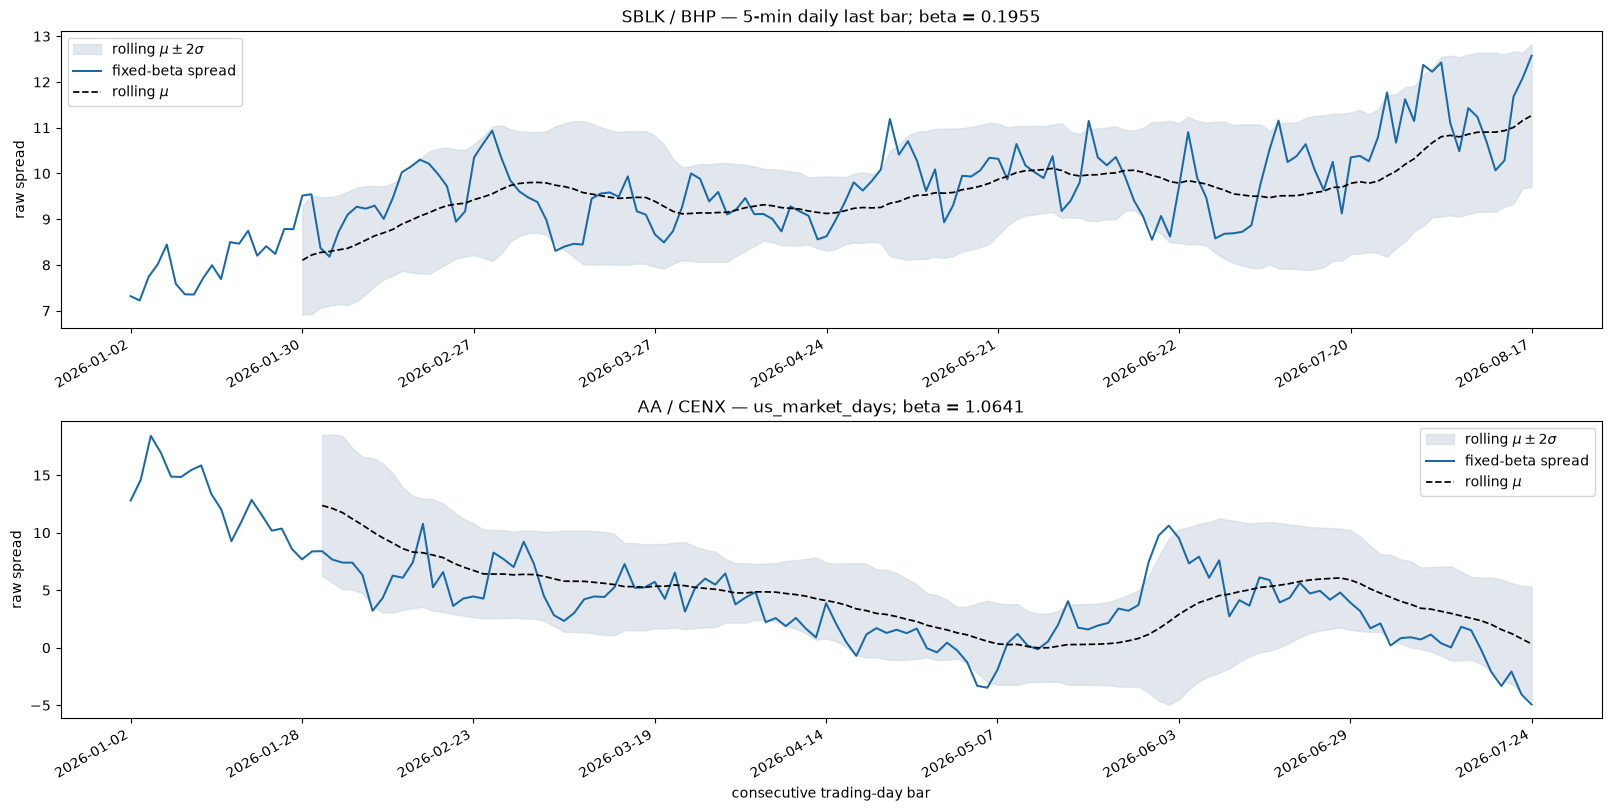

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=False, constrained_layout=True)
for ax, frame, beta, title in [
    (axes[0], sblk_bhp_display, sblk_bhp_display_beta, 'SBLK / BHP — 5-min daily last bar'),
    (axes[1], aa_cenx_display, aa_cenx_display_beta, 'AA / CENX — us_market_days'),
]:
    bars = frame['trading_bar']
    upper = frame['mu'] + 2 * frame['sigma']
    lower = frame['mu'] - 2 * frame['sigma']
    ax.fill_between(bars, lower, upper, color='#cbd5e1', alpha=0.55, label=r'rolling $\mu\pm2\sigma$')
    ax.plot(bars, frame['spread'], color='#1769aa', lw=1.45, label='fixed-beta spread')
    ax.plot(bars, frame['mu'], color='black', lw=1.25, ls='--', label=r'rolling $\mu$')
    ax.set(title=f'{title}; beta = {beta:.4f}', ylabel='raw spread')
    ax.legend(loc='best')
    ticks = np.unique(np.linspace(0, len(frame) - 1, min(9, len(frame)), dtype=int))
    ax.set_xticks(ticks, frame['date'].dt.strftime('%Y-%m-%d').iloc[ticks], rotation=30, ha='right')
axes[1].set_xlabel('consecutive trading-day bar')
print('SBLK/BHP:', sblk_bhp_display['date'].min().date(), 'to', sblk_bhp_display['date'].max().date())
print('AA/CENX:', aa_cenx_display['date'].min().date(), 'to', aa_cenx_display['date'].max().date())
plt.show()

### 6.3 状态图（下一格代码）

每个配对都使用第 5 节相同的上、下两层：上层是 z-score 与中性区；下层是 20 日 rolling $\hat\kappa$。蓝色代表当前窗口证据偏向距离收缩，红色代表偏向距离扩张。重点不是某一根短暂越过零，而是观察红色/正值是否在失效期间持续。

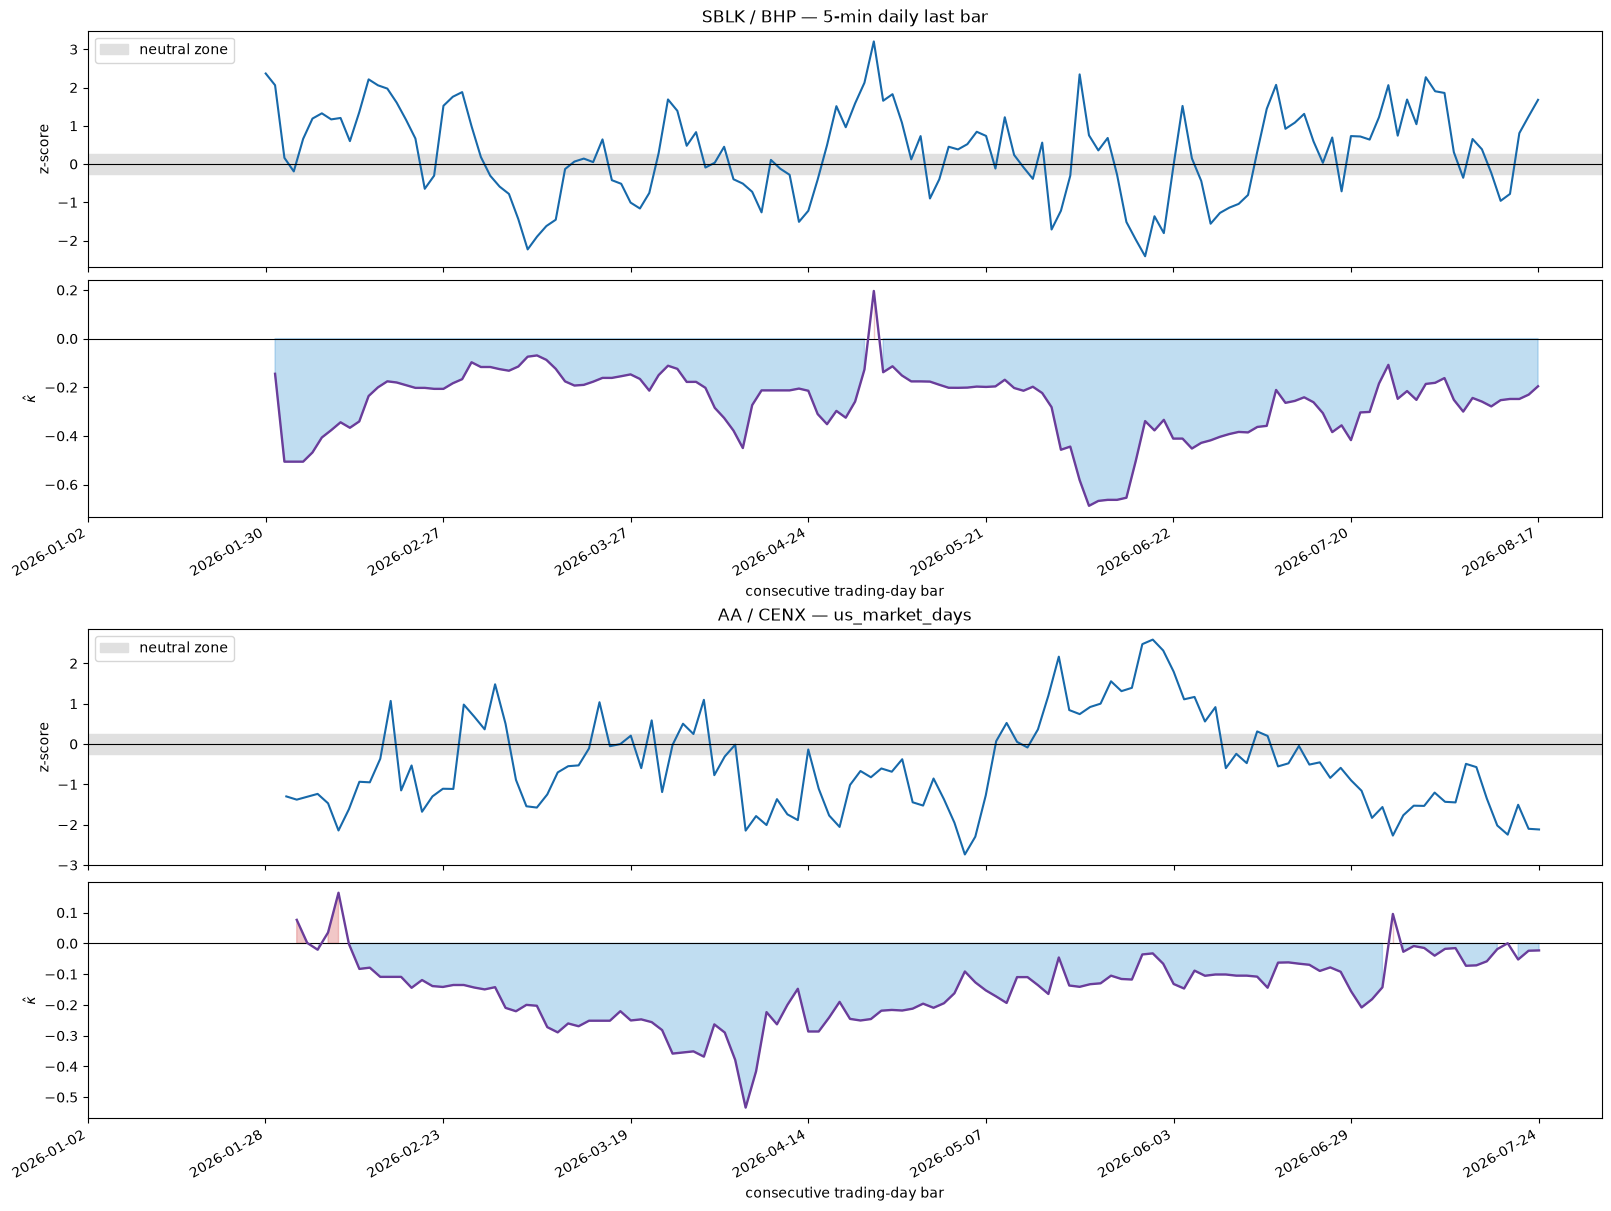

In [16]:
fig, axes = plt.subplots(4, 1, figsize=(16, 12), constrained_layout=True)
# 每个配对的上、下两层共享同一条 trading-bar x 轴，避免视觉缩放不一致。
axes[1].sharex(axes[0])
axes[3].sharex(axes[2])
for z_ax, k_ax, frame, title in [
    (axes[0], axes[1], sblk_bhp_display, 'SBLK / BHP — 5-min daily last bar'),
    (axes[2], axes[3], aa_cenx_display, 'AA / CENX — us_market_days'),
]:
    bars = frame['trading_bar']
    z_ax.axhspan(-NEUTRAL_BOUNDARY, NEUTRAL_BOUNDARY, color='0.88', zorder=0, label='neutral zone')
    z_ax.plot(bars, frame['zscore'], color='#1769aa', lw=1.5)
    z_ax.axhline(0, color='black', lw=0.8)
    z_ax.set(title=title, ylabel='z-score')
    z_ax.tick_params(axis='x', labelbottom=False)
    z_ax.legend(loc='upper left')
    k_ax.axhline(0, color='black', lw=0.8)
    k_ax.plot(bars, frame['kappa_hat'], color='#6a3d9a', lw=1.7)
    k_ax.fill_between(bars, 0, frame['kappa_hat'], where=frame['kappa_hat'] < 0,
                      color='#4c9ed9', alpha=0.35)
    k_ax.fill_between(bars, 0, frame['kappa_hat'], where=frame['kappa_hat'] > 0,
                      color='#d95f5f', alpha=0.35)
    k_ax.set(ylabel=r'$\hat\kappa$')
    ticks = np.unique(np.linspace(0, len(frame) - 1, min(9, len(frame)), dtype=int))
    k_ax.set_xticks(ticks, frame['date'].dt.strftime('%Y-%m-%d').iloc[ticks], rotation=30, ha='right')
axes[1].set_xlabel('consecutive trading-day bar')
axes[3].set_xlabel('consecutive trading-day bar')
plt.show()

### 6.4 Rolling-mean derivative / bar（与 Fixed Beta dashboard 同口径）

每个点都按 `（当前 spread − window 前 spread）/ window` 计算。这里两组展示数据均为日频，因此 window 为 20 个交易日；若输入是 5 分钟共同 bar，dashboard 使用相同公式但 window 为 $20\times79=1580$ 根 5 分钟 bar。

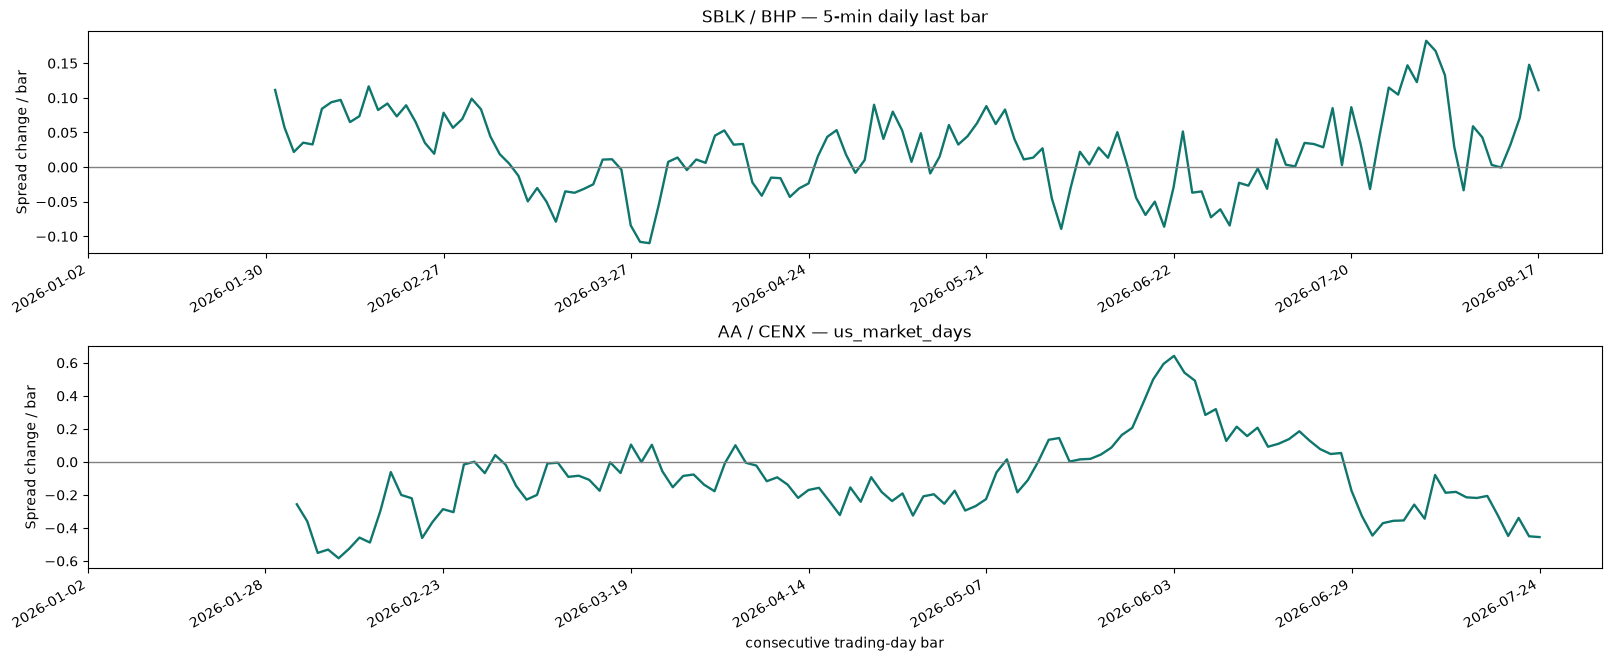

In [17]:
# 与 quant_dashboard_fixed_beta.py 的 derivative_fig 同一公式、零轴和颜色口径。
fig, axes = plt.subplots(2, 1, figsize=(16, 6.5), sharex=False, constrained_layout=True)
for ax, frame, title in [
    (axes[0], sblk_bhp_display, 'SBLK / BHP — 5-min daily last bar'),
    (axes[1], aa_cenx_display, 'AA / CENX — us_market_days'),
]:
    bars = frame['trading_bar']
    ax.plot(bars, frame['mean_derivative'], color='#0f766e', lw=1.7)
    ax.axhline(0, color='gray', lw=1.0)
    ax.set(title=title, ylabel='Spread change / bar')
    ticks = np.unique(np.linspace(0, len(frame) - 1, min(9, len(frame)), dtype=int))
    ax.set_xticks(ticks, frame['date'].dt.strftime('%Y-%m-%d').iloc[ticks], rotation=30, ha='right')
axes[1].set_xlabel('consecutive trading-day bar')
plt.show()